 Queremos estimar el precio de las casas que se publiquen el año que viene. ¿Qué modelo usarías: regresión lineal o bosque?

Carga el CSV, convierte la fecha y prepara variables numéricas y dummies para las categorías.

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ruta_datos = Path("data/raw/casas_10000.csv")
if not ruta_datos.is_file():
    ruta_datos = Path("../data/raw/casas_10000.csv")

df = pd.read_csv(ruta_datos)
df["fecha_publicacion"] = pd.to_datetime(df["fecha_publicacion"], errors="coerce")
fecha_inicio = df["fecha_publicacion"].min()
df["fecha_dias"] = (df["fecha_publicacion"] - fecha_inicio).dt.days
df = df.drop(columns=["id", "dias_en_venta"], errors="ignore")
df = pd.get_dummies(df, columns=["barrio", "tipo"], dtype=int)
df.head()

,fecha_publicacion,latitud,longitud,distancia_centro_km,metros,habitaciones,banos,antiguedad,ascensor,terraza,...,barrio_Afueras,barrio_Centro,barrio_Este,barrio_Norte,barrio_Oeste,barrio_Sur,tipo_chalet,tipo_estudio,tipo_piso,tipo_ático
0,2019-01-01,40.49816,-3.79204,11.71,59,2,1,15,1,1,...,1,0,0,0,0,0,0,0,1,0
1,2019-01-01,40.48552,-3.78282,10.14,139,4,2,0,1,1,...,1,0,0,0,0,0,1,0,0,0
2,2019-01-02,40.43006,-3.68737,2.02,46,1,1,76,0,0,...,0,1,0,0,0,0,0,0,1,0
3,2019-01-02,40.41869,-3.71814,1.23,91,3,1,49,1,0,...,0,1,0,0,0,0,0,0,1,0
4,2019-01-03,40.50784,-3.79378,12.65,159,5,2,9,0,1,...,1,0,0,0,0,0,1,0,0,0


Agrupa los registros por año de publicación y cuenta cuántos anuncios hay en cada año.

In [9]:
resumen_anios = (
    df.dropna(subset=["fecha_publicacion"])
      .assign(anio=lambda datos: datos["fecha_publicacion"].dt.year)
      .groupby("anio")
      .size()
      .rename("cantidad_registros")
      .reset_index()
)
resumen_anios

,anio,cantidad_registros
0,2019,1616
1,2020,1716
2,2021,1630
3,2022,1671
4,2023,1691
5,2024,1676


Calcula y grafica el precio medio de las viviendas para cada año registrado.

,mes,precio_medio
0,2019-01-01,179711.864407
1,2019-02-01,198931.623932
2,2019-03-01,181937.931034
3,2019-04-01,207100.000000
4,2019-05-01,205870.748299
...,...,...
67,2024-08-01,276625.000000
68,2024-09-01,279519.685039
69,2024-10-01,263957.746479
70,2024-11-01,230701.492537


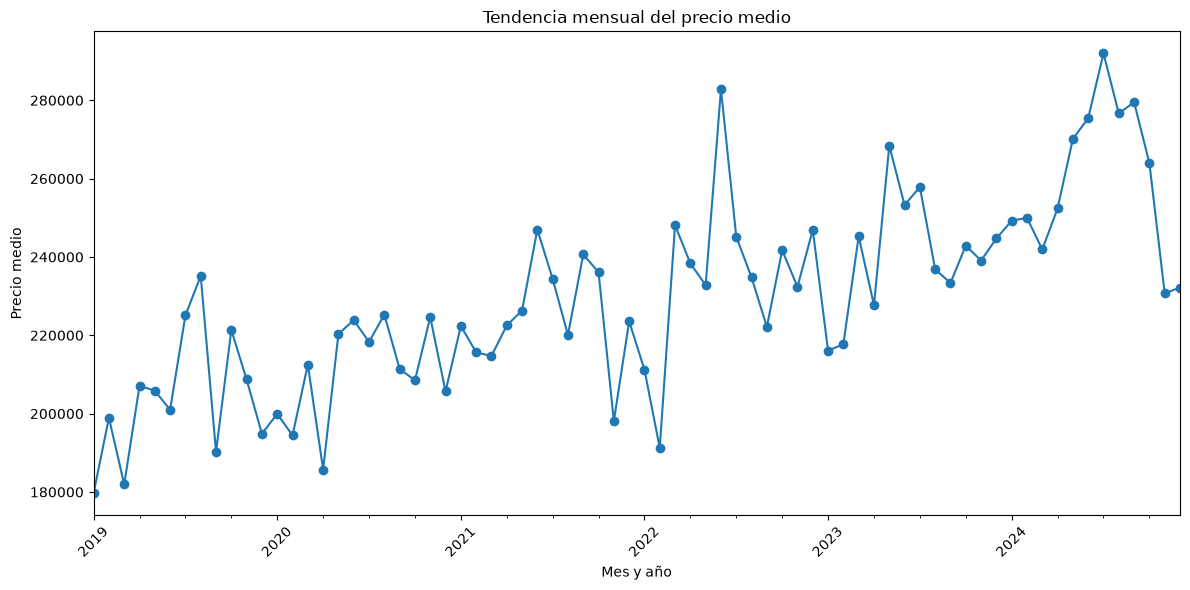

In [10]:
# Precio medio mensual: el eje temporal incluye año y mes.
precio_medio_mensual = (
    df.dropna(subset=["fecha_publicacion", "precio"])
      .assign(mes=lambda datos: datos["fecha_publicacion"].dt.to_period("M").dt.to_timestamp())
      .groupby("mes")["precio"]
      .mean()
      .rename("precio_medio")
      .reset_index()
)
display(precio_medio_mensual)

ax = precio_medio_mensual.plot(
    x="mes", y="precio_medio", marker="o", legend=False,
    title="Tendencia mensual del precio medio", figsize=(12, 6)
)
ax.set_xlabel("Mes y año")
ax.set_ylabel("Precio medio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Calcula y grafica el precio medio mensual de las viviendas para cada mes registrado.

,mes,precio_medio
0,2019-01-01,179711.864407
1,2019-02-01,198931.623932
2,2019-03-01,181937.931034
3,2019-04-01,207100.000000
4,2019-05-01,205870.748299
...,...,...
67,2024-08-01,276625.000000
68,2024-09-01,279519.685039
69,2024-10-01,263957.746479
70,2024-11-01,230701.492537


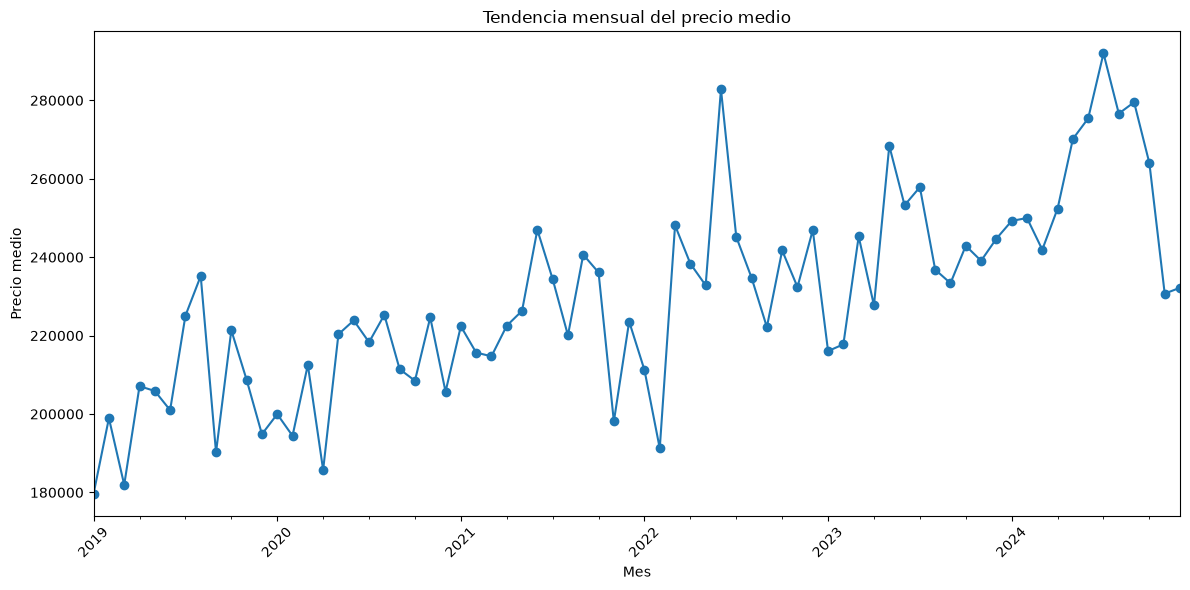

In [11]:
precio_medio_mensual = (
    df.dropna(subset=["fecha_publicacion", "precio"])
      .assign(mes=lambda datos: datos["fecha_publicacion"].dt.to_period("M").dt.to_timestamp())
      .groupby("mes")["precio"]
      .mean()
      .rename("precio_medio")
      .reset_index()
)
display(precio_medio_mensual)

ax = precio_medio_mensual.plot(
    x="mes", y="precio_medio", marker="o", legend=False,
    title="Tendencia mensual del precio medio", figsize=(12, 6)
)
ax.set_xlabel("Mes")
ax.set_ylabel("Precio medio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

entrenamos ambos modelos con los mismos datos 

In [12]:
# Evaluación temporal: entrenamiento 2019–2022 y prueba con los años restantes.
datos = df.dropna(subset=["fecha_publicacion", "precio"]).copy()
entrenamiento = datos[datos["fecha_publicacion"].dt.year.between(2019, 2022)].copy()
prueba = datos[datos["fecha_publicacion"].dt.year >= 2023].copy()
columnas_excluidas = {"precio", "id", "fecha_publicacion", "dias_en_venta"}
caracteristicas = [col for col in datos.columns if col not in columnas_excluidas]
X_train, y_train = entrenamiento[caracteristicas], entrenamiento["precio"]
X_test, y_test = prueba[caracteristicas], prueba["precio"]
print(f"Entrenamiento (2019–2022): {len(entrenamiento):,} filas")
print(f"Prueba (2023 en adelante): {len(prueba):,} filas")

Entrenamiento (2019–2022): 6,633 filas
Prueba (2023 en adelante): 3,367 filas


Entrenamos los modelos con publicaciones de 2019–2022 y comparamos predicciones mensuales hasta 2024 con precios reales mensuales disponibles.

Entrenamiento (2019–2022): 6,633 filas
Test (2023 en adelante): 3,367 filas


/tmp/ipykernel_7981/2711050064.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predicciones_anuales.round(2))


,mes,predicción lineal,predicción bosque
0,2019-01-01,126313.20,144573.33
1,2019-02-01,127154.64,158026.67
2,2019-03-01,127914.64,158263.33
3,2019-04-01,128756.07,158313.33
4,2019-05-01,129570.36,160360.00
...,...,...,...
67,2024-08-01,181657.80,174226.67
68,2024-09-01,182499.24,174226.67
69,2024-10-01,183313.53,174226.67
70,2024-11-01,184154.96,174226.67


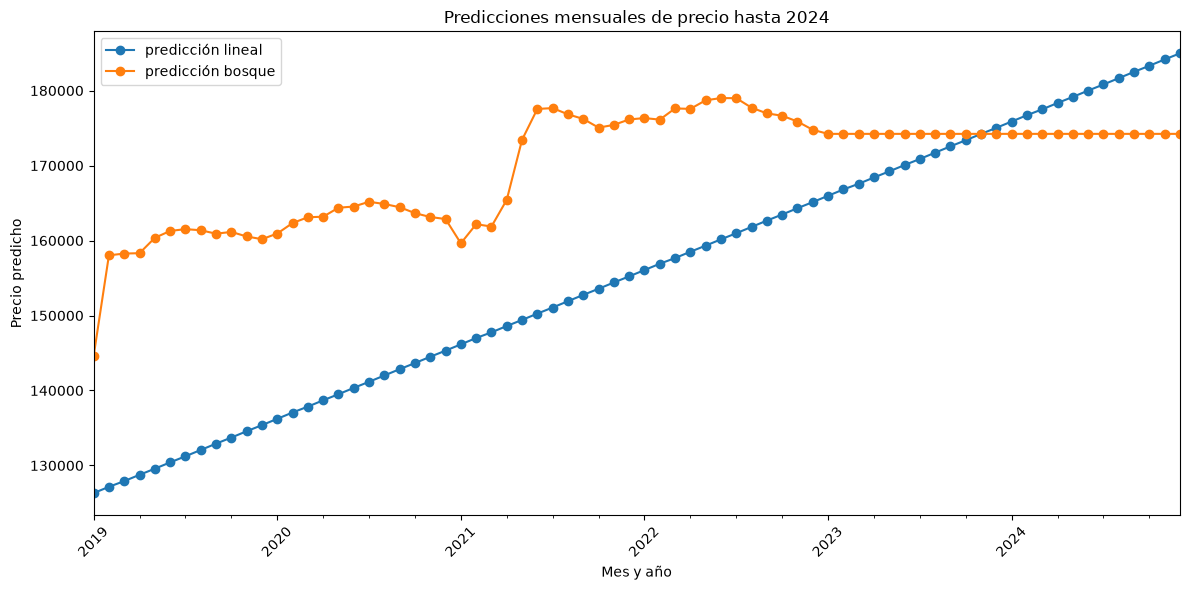

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Entrenamiento solo 2019–2022; el resto de fechas disponible se reserva para test.
datos_modelo = datos.copy()
train = datos_modelo[datos_modelo["fecha_publicacion"].dt.year.between(2019, 2022)].copy()
test = datos_modelo[datos_modelo["fecha_publicacion"].dt.year >= 2023].copy()
columnas_modelo = [col for col in train.columns if col not in {"precio", "fecha_publicacion"}]
X_train_modelo = train[columnas_modelo]
y_train_modelo = train["precio"]
X_test_modelo = test[columnas_modelo]
y_test_modelo = test["precio"]

modelo_lineal = LinearRegression().fit(X_train_modelo, y_train_modelo)
modelo_bosque = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train_modelo, y_train_modelo)
print(f"Entrenamiento (2019–2022): {len(train):,} filas")
print(f"Test (2023 en adelante): {len(test):,} filas")

# Perfil típico: medianas numéricas y categoría más frecuente.
casa_tipo = X_train_modelo.median().to_frame().T
for prefijo in ["barrio_", "tipo_"]:
    dummies = [c for c in columnas_modelo if c.startswith(prefijo)]
    if dummies:
        frecuente = X_train_modelo[dummies].mean().idxmax()
        casa_tipo.loc[:, dummies] = 0
        casa_tipo.loc[:, frecuente] = 1

# Predicción mensual hasta diciembre de 2024.
meses_prediccion = pd.date_range("2019-01-01", "2024-12-01", freq="MS")
filas_resultado = []
for fecha in meses_prediccion:
    ejemplo = casa_tipo.copy()
    ejemplo["fecha_dias"] = (fecha - fecha_inicio).days
    ejemplo = ejemplo[columnas_modelo]
    filas_resultado.append({
        "mes": fecha,
        "predicción lineal": modelo_lineal.predict(ejemplo)[0],
        "predicción bosque": modelo_bosque.predict(ejemplo)[0],
    })
predicciones_anuales = pd.DataFrame(filas_resultado)
display(predicciones_anuales.round(2))

ax = predicciones_anuales.plot(
    x="mes", y=["predicción lineal", "predicción bosque"], marker="o",
    title="Predicciones mensuales de precio hasta 2024", figsize=(12, 6)
)
ax.set_xlabel("Mes y año")
ax.set_ylabel("Precio predicho")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Compara para cada mes de 2024 la predicción de los modelos con el precio real medio de las tres viviendas más similares. Se muestran también los errores absolutos.

/tmp/ipykernel_7981/4221487910.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparacion.round(2))


,mes,predicción lineal,predicción bosque,precio real (media 3 similares),precio medio real mensual
0,2019-01-01,126313.20,144573.33,133000.00,179711.86
1,2019-02-01,127154.64,158026.67,145000.00,198931.62
2,2019-03-01,127914.64,158263.33,113666.67,181937.93
3,2019-04-01,128756.07,158313.33,121333.33,207100.00
4,2019-05-01,129570.36,160360.00,147333.33,205870.75
...,...,...,...,...,...
67,2024-08-01,181657.80,174226.67,95000.00,276625.00
68,2024-09-01,182499.24,174226.67,112666.67,279519.69
69,2024-10-01,183313.53,174226.67,148333.33,263957.75
70,2024-11-01,184154.96,174226.67,137666.67,230701.49


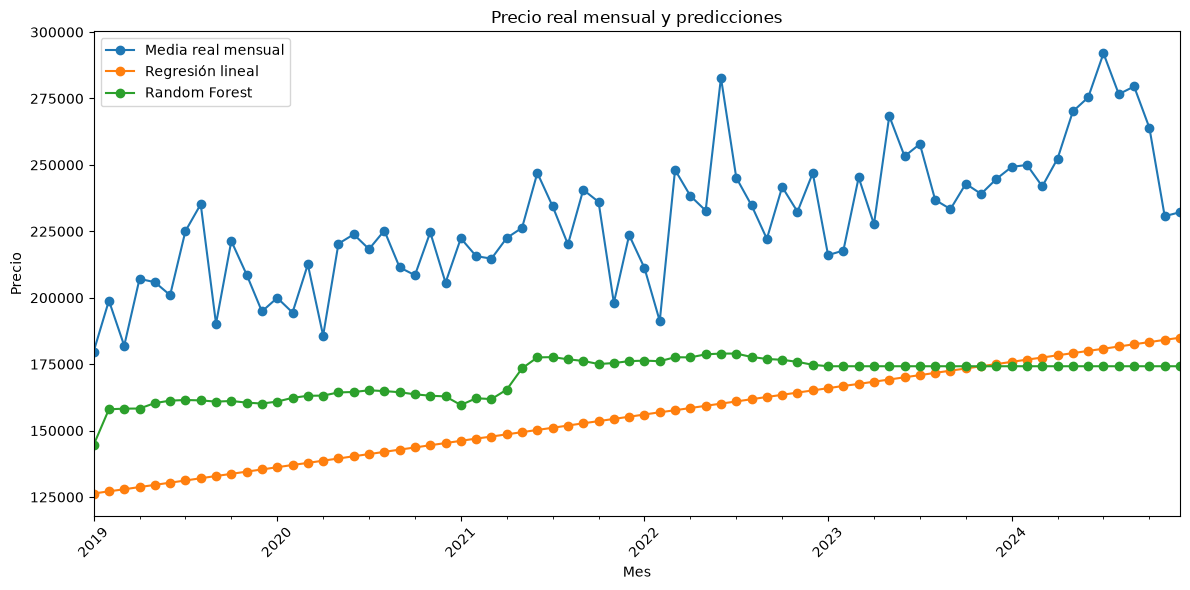

/tmp/ipykernel_7981/4221487910.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparacion_modelos_2024.round(2))


,mes,predicción lineal,predicción bosque,precio real (media 3 similares),error lineal,error bosque
60,2024-01-01,175876.34,174226.67,114666.67,61209.68,59560.00
61,2024-02-01,176717.78,174226.67,162000.00,14717.78,12226.67
62,2024-03-01,177504.92,174226.67,152333.33,25171.59,21893.33
63,2024-04-01,178346.36,174226.67,93666.67,84679.69,80560.00
64,2024-05-01,179160.65,174226.67,90666.67,88493.98,83560.00
65,2024-06-01,180002.08,174226.67,199000.00,18997.92,24773.33
66,2024-07-01,180816.37,174226.67,102000.00,78816.37,72226.67
67,2024-08-01,181657.80,174226.67,95000.00,86657.80,79226.67
68,2024-09-01,182499.24,174226.67,112666.67,69832.57,61560.00
69,2024-10-01,183313.53,174226.67,148333.33,34980.19,25893.33


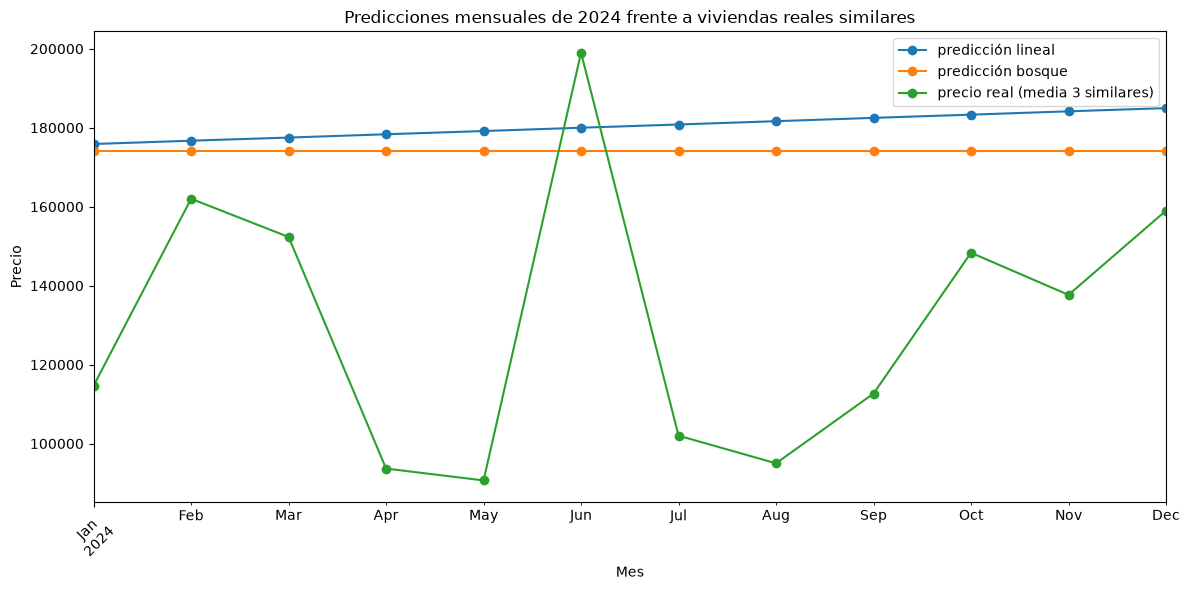

In [14]:
# Comparación real mensual y gráfica mensual de predicciones frente a anuncios reales.
import numpy as np

columnas_similitud = [
    c for c in columnas_modelo
    if not c.startswith(("barrio_", "tipo_")) and c != "fecha_dias"
] + [c for c in columnas_modelo if c.startswith(("barrio_", "tipo_"))]
referencia = casa_tipo[columnas_similitud].astype(float)
valores = datos_modelo[columnas_similitud].astype(float)
medianas = X_train_modelo[columnas_similitud].median().astype(float)
desviaciones = X_train_modelo[columnas_similitud].std().replace(0, 1).fillna(1).astype(float)
columnas_numericas_dist = [c for c in columnas_similitud if not c.startswith(("barrio_", "tipo_"))]
valores_escalados = valores.copy()
referencia_escalada = referencia.copy()
valores_escalados[columnas_numericas_dist] = (valores[columnas_numericas_dist] - medianas[columnas_numericas_dist]) / desviaciones[columnas_numericas_dist]
referencia_escalada[columnas_numericas_dist] = (referencia[columnas_numericas_dist] - medianas[columnas_numericas_dist]) / desviaciones[columnas_numericas_dist]

registros_reales = []
for mes in pd.date_range("2019-01-01", "2024-12-01", freq="MS"):
    mascara = datos_modelo["fecha_publicacion"].dt.to_period("M") == mes.to_period("M")
    indices = datos_modelo.index[mascara]
    if len(indices) == 0:
        continue
    distancias = np.sqrt(((valores_escalados.loc[indices] - referencia_escalada.iloc[0]) ** 2).sum(axis=1))
    cercanos = distancias.nsmallest(min(3, len(distancias))).index
    registros_reales.append({
        "mes": mes,
        "precio real (media 3 similares)": datos_modelo.loc[cercanos, "precio"].mean(),
        "precio medio real mensual": datos_modelo.loc[indices, "precio"].mean(),
    })
precios_reales_cercanos = pd.DataFrame(registros_reales)
comparacion = predicciones_anuales.merge(precios_reales_cercanos, on="mes", how="left")
display(comparacion.round(2))

ax = comparacion.plot(x="mes", y=["precio medio real mensual", "predicción lineal", "predicción bosque"], marker="o", figsize=(12, 6), title="Precio real mensual y predicciones")
ax.set_xlabel("Mes")
ax.set_ylabel("Precio")
ax.legend(["Media real mensual", "Regresión lineal", "Random Forest"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Errores mensuales en 2024 contra la referencia de viviendas más similares.
fila_2024 = comparacion[comparacion["mes"].dt.year == 2024].copy()
comparacion_modelos_2024 = fila_2024[["mes", "predicción lineal", "predicción bosque", "precio real (media 3 similares)"]].copy()
comparacion_modelos_2024["error lineal"] = (comparacion_modelos_2024["predicción lineal"] - comparacion_modelos_2024["precio real (media 3 similares)"]).abs()
comparacion_modelos_2024["error bosque"] = (comparacion_modelos_2024["predicción bosque"] - comparacion_modelos_2024["precio real (media 3 similares)"]).abs()
display(comparacion_modelos_2024.round(2))

ax = comparacion_modelos_2024.plot(x="mes", y=["predicción lineal", "predicción bosque", "precio real (media 3 similares)"], marker="o", figsize=(12, 6), title="Predicciones mensuales de 2024 frente a viviendas reales similares")
ax.set_xlabel("Mes")
ax.set_ylabel("Precio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()